# Tutorial 1 — Reading and visualising common rheological datasets

This tutorial shows how to load rheometer exports with `hermes_rheo` and plot them:

1. A [TA Instruments](https://www.tainstruments.com/) [TRIOS](https://www.tainstruments.com/support/software-downloads-support/downloads/) `.txt` export containing a single creep test.
2. A [TRIOS](https://www.tainstruments.com/support/software-downloads-support/downloads/) `.txt` export containing several test types (amplitude sweep,
   frequency sweep, flow ramp).
3. An [Anton Paar](https://www.anton-paar.com/us-en/) [RheoCompass](https://www.anton-paar.com/us-en/products/details/rheometer-software-rheocompass/) `.csv` export of a time-temperature superposition (tTS) series of
   frequency sweeps.

:::{seealso}
- [`hermes_rheo.file_readers`](https://3mcloud.github.io/hermes-rheo/file_readers.html): reader API reference.
- Tutorial 3 covers OWChirp experiments, which need the dedicated
  [`OWChirpAnalysis`](https://3mcloud.github.io/hermes-rheo/transforms.html#module-hermes_rheo.transforms.owchirp_analysis) transform.
:::

:::{important}
**Exporting [TRIOS](https://www.tainstruments.com/support/software-downloads-support/downloads/) files.** `TriosRheoReader`:

- **[TRIOS](https://www.tainstruments.com/support/software-downloads-support/downloads/) 5 and earlier:** *Send To LIMS*.

  ![[TRIOS](https://www.tainstruments.com/support/software-downloads-support/downloads/) Send To LIMS export](attachment:trios_export_lims.png)

- **[TRIOS](https://www.tainstruments.com/support/software-downloads-support/downloads/) 6.0 and later:** *Export* → *To Plain Text (full)…*.

  ![[TRIOS](https://www.tainstruments.com/support/software-downloads-support/downloads/) Export to Plain Text (full)](attachment:trios_export_txt_full.png)

The plain *To Plain Text* option strips important metadata.
[TRIOS](https://www.tainstruments.com/support/software-downloads-support/downloads/) is a free download from [TA Instruments](https://www.tainstruments.com/).
:::

:::{note}
**[RheoCompass](https://www.anton-paar.com/us-en/products/details/rheometer-software-rheocompass/) files.** `RheoCompassReader` reads the tab-separated `.csv` table export of
[RheoCompass](https://www.anton-paar.com/us-en/products/details/rheometer-software-rheocompass/). Each interval block (`Interval and data points:` header followed by the
column names and units) becomes one measurement, and the default axes are chosen
from the columns present (oscillatory sweep, flow sweep or time series).
:::
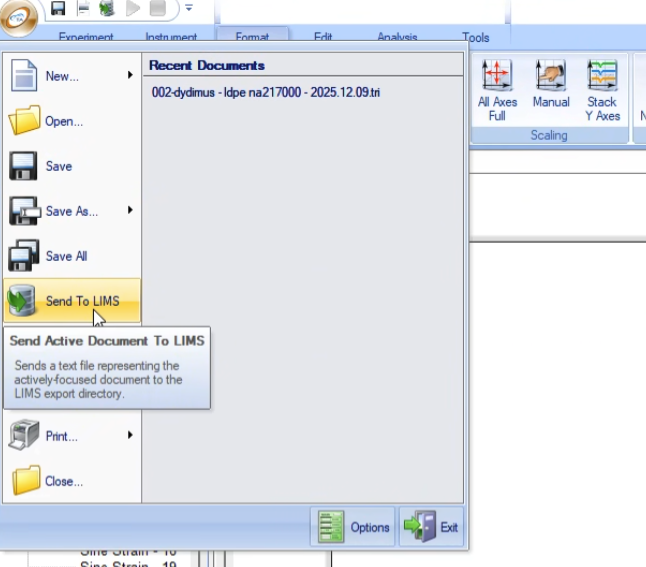
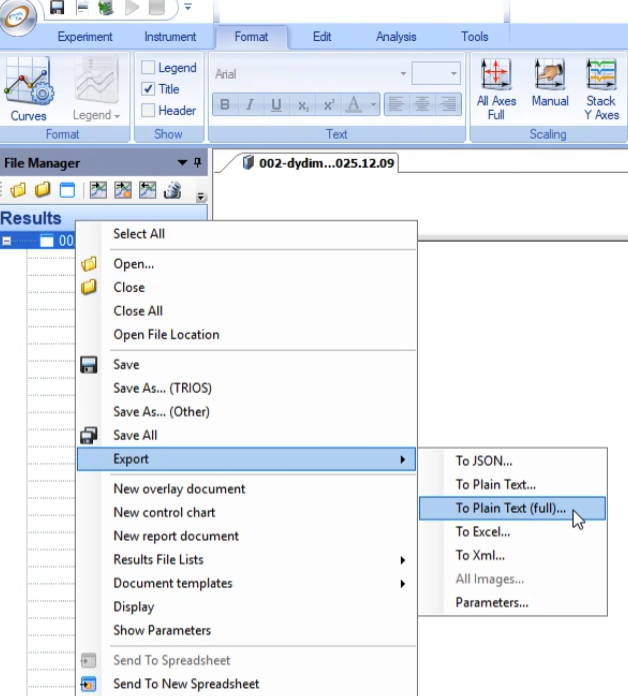

## Supported software

| Software | File type | Reader class |
|---|---|---|
| [TRIOS](https://www.tainstruments.com/support/software-downloads-support/downloads/) | `.txt` (*Send To LIMS* or *To Plain Text (full)*) | `TriosRheoReader` |
| [RheoCompass](https://www.anton-paar.com/us-en/products/details/rheometer-software-rheocompass/) | `.csv` | `RheoCompassReader` |

All readers are used the same way: `read_file` takes the file path and, optionally,
the reader class. If no reader is given, it is chosen from the file extension
(`.txt` → `TriosRheoReader`, `.csv` → `RheoCompassReader`).
For other formats, write a custom reader and reuse the transforms unchanged.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from hermes_rheo import RheoCompassReader, TriosRheoReader, read_file
from hermes_rheo.visualization import get_unit, use_science_style

use_science_style()  # publication-style Matplotlib settings
DATA = Path("tutorial_data")  # run this notebook from tutorial_notebooks/

## 1. A file with a single test

`read_file` returns an `ExperimentSet` when all measurements in the file are of the
same kind. Each measurement holds one or more datasets; for a creep step the
dataset holds `strain` as a function of `time`, so it can be plotted directly.
Axis labels and units are read from the file.

In [2]:
creep = read_file(
    DATA / "dhr_trios_creep.txt",
    file_reader=TriosRheoReader,
    create_composite_datasets=True,
)
print(creep)

ExperimentSet
-------------

Summary
-------
Number of Experiments: 1

Varied Conditions
----------------

index	n_rep	method	Data Types	
0	1	Creep - 1	strain(%)=f(time[min]) (483 points)	




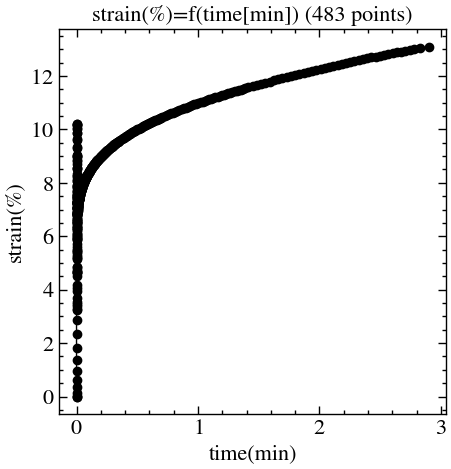

In [3]:
creep_dataset = creep.measurements[0].datasets[0]
fig, ax = creep_dataset.visualize(marker="o", linewidth=1)

## 2. A file with several test types

A single file can hold different tests in sequence, here an amplitude sweep, a
frequency sweep and a flow ramp. They have different axes, so they cannot be
grouped in one `ExperimentSet`. Passing `to_experiments=False` returns a
`MeasurementSet` instead, where each measurement keeps the axes that suit its test:

- amplitude sweep: storage modulus vs. oscillation strain
- frequency sweep: storage modulus vs. angular frequency
- flow ramp: viscosity vs. shear rate

:::{tip}
To force the same axes on every measurement and keep the `ExperimentSet` structure,
read with `default_coords="uniform"` and select the axes later with
`switch_coordinates()`.
:::

In [4]:
tests = read_file(
    DATA / "dhr_trios_multi_technique.txt",
    file_reader=TriosRheoReader,
    create_composite_datasets=True,
    to_experiments=False,
)

for measurement in tests.measurements:
    dataset = measurement.datasets[0]
    print(
        f"{measurement.conditions['method']:<22}"
        f"{dataset.dependent_variable_name} vs. {dataset.independent_variable_name}"
    )

Amplitude sweep - 1   storage modulus vs. oscillation strain (cmd)
Frequency sweep - 2   storage modulus vs. angular frequency
Flow ramp - 3         viscosity vs. shear rate


### Selecting and plotting a measurement

Measurements are indexed in the order they appear in the file. `visualize()` plots
a dataset on its default axes and returns the Matplotlib figure and axes for
further formatting.

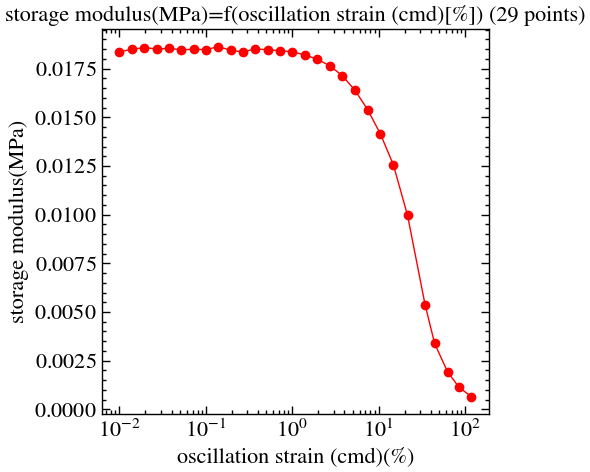

In [5]:
amplitude_sweep, frequency_sweep, flow_ramp = (m.datasets[0] for m in tests.measurements)

fig, ax = amplitude_sweep.visualize(marker="o", linewidth=1, color="red")
ax.set_xscale("log")

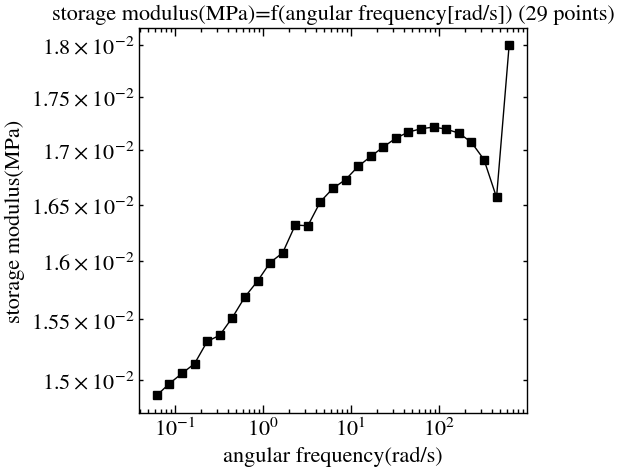

In [6]:
fig, ax = frequency_sweep.visualize(marker="s", linewidth=1, color="black")
ax.set_xscale("log")
ax.set_yscale("log")

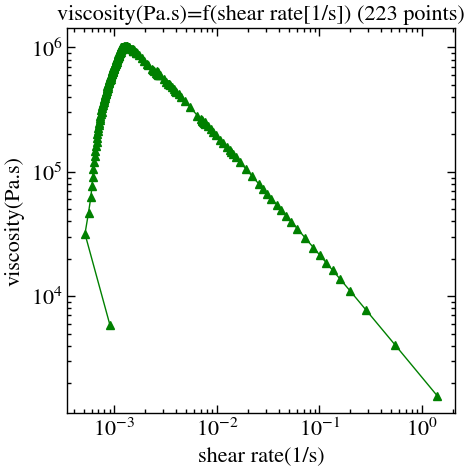

In [7]:
fig, ax = flow_ramp.visualize(marker="^", linewidth=1, color="green")
ax.set_xscale("log")
ax.set_yscale("log")

### Switching axes and accessing the data

Every dataset stores all the columns of its test. `switch_coordinates()` changes the
plotted pair, and the arrays are available as `x_values` (independent variable)
and `y_values` (dependent variable).

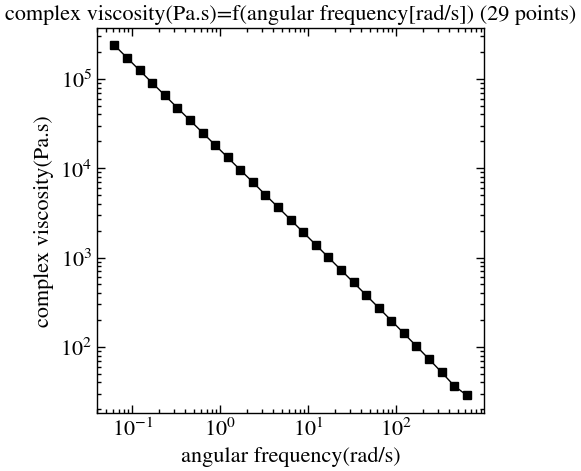

In [8]:
frequency_sweep.switch_coordinates("angular frequency", "complex viscosity")
fig, ax = frequency_sweep.visualize(marker="s", linewidth=1, color="black")
ax.set_xscale("log")
ax.set_yscale("log")

In [9]:
print(f"{frequency_sweep.independent_variable_name}: {frequency_sweep.x_values[:3]}")
print(f"{frequency_sweep.dependent_variable_name}: {frequency_sweep.y_values[:3]}")

angular frequency: [+628.3185 +452.1964 +325.4363]
complex viscosity: [+28.7017 +36.6608 +51.9980]


## 3. A [RheoCompass](https://www.anton-paar.com/us-en/products/details/rheometer-software-rheocompass/) file

`RheoCompassReader` is used exactly like `TriosRheoReader`. The file below is a tTS
series: isothermal frequency sweeps measured at different temperatures, one
measurement per interval. Plotting a few of them shows how the moduli shift
with temperature; `visualize(axes=...)` draws each sweep on a shared axis and
labels it from the dataset. Tutorial 4 builds the master curve from this kind of data.

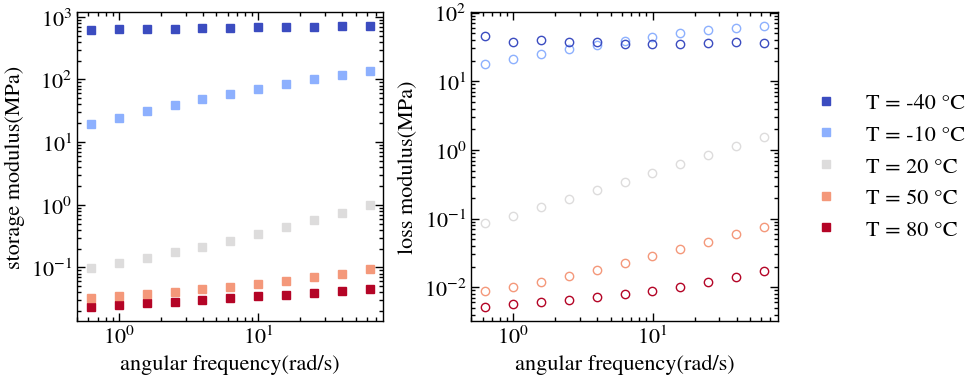

In [10]:
experiment = read_file(
    DATA / "mcr702e_rheocompass_tts.csv",
    file_reader=RheoCompassReader,
    create_composite_datasets=True,
)

isotherms = experiment.measurements[4::6]  # every 6th temperature, from 80 °C down
colors = plt.cm.coolwarm(np.linspace(1, 0, len(isotherms)))  # red = hot, blue = cold

fig, (ax_storage, ax_loss) = plt.subplots(1, 2, figsize=(10, 4))
for measurement, color in zip(isotherms, colors):
    sweep = measurement.datasets[0]
    temperature = sweep.data_arrays[sweep.data_array_names.index("temperature")].mean()
    label = f"T = {temperature:.0f} {get_unit(sweep, 'temperature')}"
    sweep.visualize(axes=ax_storage, marker="s", linestyle="none", color=color, label=label)
    sweep.switch_coordinates("angular frequency", "loss modulus")
    sweep.visualize(axes=ax_loss, marker="o", linestyle="none", color=color, mfc="none")

for ax in (ax_storage, ax_loss):
    ax.set_xscale("log")
    ax.set_yscale("log")
handles, labels = ax_storage.get_legend_handles_labels()
ax_loss.legend(handles[::-1], labels[::-1], loc="center left", bbox_to_anchor=(1.02, 0.5))  # cold on top
fig.tight_layout()
plt.show()

### Customising the plot

`visualize()` returns standard Matplotlib objects, so any element can be changed
afterwards. Below, G′ and G″ share one axis, and the default labels are replaced
by symbols while the units are still read from the dataset.

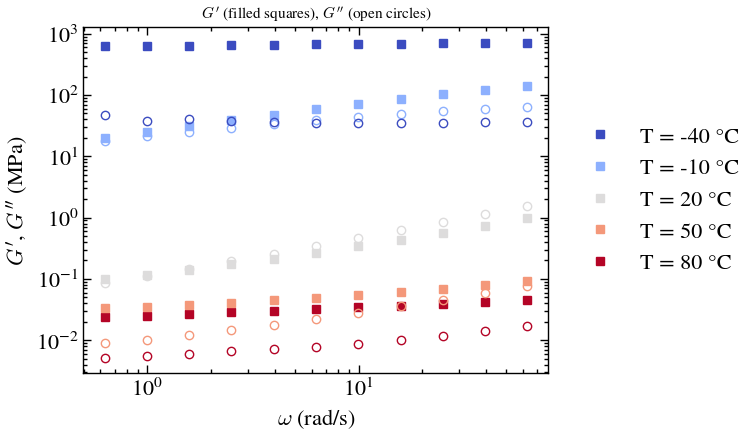

In [11]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for measurement, color in zip(isotherms, colors):
    sweep = measurement.datasets[0]
    temperature = sweep.data_arrays[sweep.data_array_names.index("temperature")].mean()
    label = f"T = {temperature:.0f} {get_unit(sweep, 'temperature')}"
    sweep.switch_coordinates("angular frequency", "storage modulus")
    sweep.visualize(axes=ax, marker="s", linestyle="none", color=color, label=label)
    sweep.switch_coordinates("angular frequency", "loss modulus")
    sweep.visualize(axes=ax, marker="o", linestyle="none", color=color, mfc="none", label="_")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel(rf"$\omega$ ({get_unit(sweep, 'angular frequency')})")
ax.set_ylabel(rf"$G'$, $G''$ ({get_unit(sweep, 'storage modulus')})")
ax.set_title(r"$G'$ (filled squares), $G''$ (open circles)", fontsize=11)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="center left", bbox_to_anchor=(1.02, 0.5))
plt.show()